
# AI Blog Generator — Give a Topic, Get a Complete Blog Post With an Image

**Project | AI Mini Projects Series**

**Problem:** Writing a full blog post from zero takes hours: outline, draft, SEO text and a header image.

**What this notebook does:** You give a topic. It makes an outline, writes the full blog in markdown, creates a meta description and tags, makes a header image, and saves everything as `blog.md`.

**How it works:** topic → outline → full blog → meta description + tags + image prompt → header image → save.

**Tools:** Python, Groq (openai/gpt-oss-120b), requests, Pillow, Google Colab

## Step 1: Install libraries

In [1]:
!pip install -q openai requests pillow

## Step 2: Enter Groq key

In [2]:
import os
import getpass
from openai import OpenAI

os.environ["GROQ_API_KEY"] = getpass.getpass("Enter your Groq API key: ")

client = OpenAI(
    api_key=os.environ["GROQ_API_KEY"],
    base_url="https://api.groq.com/openai/v1"
)
model_name = "openai/gpt-oss-120b"
print("Groq client ready")

Enter your Groq API key: ··········
Groq client ready


## Step 3: Helper function to call the LLM

In [3]:
def ask_llm(system_msg, user_msg, temperature=0.3):
    try:
        response = client.chat.completions.create(
            model=model_name,
            messages=[
                {"role": "system", "content": system_msg},
                {"role": "user", "content": user_msg}
            ],
            temperature=temperature
        )
        return response.choices[0].message.content
    except Exception as e:
        return "Error calling Groq: " + str(e)

## Step 4: Enter the topic, tone and length

In [4]:
topic = input("Blog topic (press Enter for sample): ").strip()
if topic == "":
    topic = "AI tools every student should know"

tone = input("Tone - friendly / professional / funny (press Enter for friendly): ").strip()
if tone == "":
    tone = "friendly"

words_text = input("How many words? (press Enter for 600): ").strip()
try:
    words = int(words_text)
except:
    words = 600

print("Topic:", topic)
print("Tone:", tone)
print("Words:", words)

Blog topic (press Enter for sample): gaming
Tone - friendly / professional / funny (press Enter for friendly): 
How many words? (press Enter for 600): 
Topic: gaming
Tone: friendly
Words: 600


## Step 5: Make the outline

In [5]:
outline = ask_llm(
    "You are a blog writer. You make clear outlines.",
    "Topic: " + topic + "\nWrite one blog title and 5 section headings as a numbered list. Nothing else."
)
print(outline)

1. **The Evolution of Gaming: From Arcades to Virtual Worlds**  
2. The Rise of Indie Games: Creativity Unleashed  
3. Multiplayer Revolution: Social Gaming in the Digital Age  
4. The Impact of Cloud Gaming on Accessibility and Performance  
5. Future Trends: AI, VR, and the Next Generation of Interactive Experiences  
6. How Gaming Shapes Culture and Community Worldwide


## Step 6: Write the full blog post

In [6]:
blog_prompt = (
    "Write a blog post of about " + str(words) + " words on this topic: " + topic + "\n"
    "Tone: " + tone + "\n"
    "Follow this outline:\n" + outline + "\n\n"
    "Rules:\n"
    "- Use markdown\n"
    "- First line is the title with a single #\n"
    "- Use ## for section headings\n"
    "- Short intro, short conclusion, short paragraphs\n"
    "- Simple English\n"
    "- Do not make up statistics or fake quotes"
)

blog = ask_llm("You write clear and helpful blog posts.", blog_prompt, 0.7)

word_count = len(blog.split())
print("Word count:", word_count, "(asked for about", words, ")")

if word_count < words * 0.7 and words >= 300:
    print("The blog is shorter than asked, expanding it once...")
    blog = ask_llm(
        "You expand blog posts without changing their structure.",
        "Expand this blog post to about " + str(words) + " words. Keep the same title and headings, and add useful detail and examples to each section. Do not make up statistics or quotes.\n\n" + blog,
        0.7
    )
    print("New word count:", len(blog.split()))

title = "Blog"
for line in blog.splitlines():
    if line.startswith("# "):
        title = line[2:].strip()
        break

print("Title:", title)

Word count: 817 (asked for about 600 )
Title: Gaming: A Friendly Look at How Play Has Changed Our World


## Step 7: Meta description, tags and image prompt

In [7]:
meta_text = ask_llm(
    "You help with blog SEO.",
    "Blog title: " + title + "\nTopic: " + topic + "\n"
    "Give exactly 3 lines:\n"
    "META: a meta description under 150 characters\n"
    "TAGS: 5 tags separated by commas\n"
    "IMAGE: one line prompt for a header picture. It must be ONE single scene with ONE clear main object and a simple background. "
    "Not a collage, not a timeline, no multiple panels. No text, letters, logos or words in the image."
)

meta = ""
tags = ""
image_prompt = ""

for line in meta_text.splitlines():
    line = line.strip()
    if line.upper().startswith("META:"):
        meta = line[5:].strip()
    elif line.upper().startswith("TAGS:"):
        tags = line[5:].strip()
    elif line.upper().startswith("IMAGE:"):
        image_prompt = line[6:].strip()

if image_prompt == "":
    image_prompt = "A clean modern illustration about " + topic

# extra words to keep the picture simple (image models are bad at collages and text)
image_prompt = image_prompt.strip().rstrip(".") + ", single scene, one main subject, digital illustration, no text, no collage"

print("Meta:", meta)
print("Tags:", tags)
print("Image prompt:", image_prompt)

Meta: Explore how gaming transformed culture, technology, and social connections in a friendly, insightful look.
Tags: gaming, culture, technology, social impact, history
Image prompt: A modern gamer holding a glowing game controller, seated on a simple dark chair against a plain gradient background, single scene, one main subject, digital illustration, no text, no collage


## Step 8: Make the header image
This asks a free online image service for 3 options (it waits at most 75 seconds, so it can not hang). If the service is slow or down, a simple banner with the title is made instead. When you see 'This cell is finished', go to the next cell.

In [8]:
import shutil
import urllib.parse
import textwrap
import requests
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from concurrent.futures import ThreadPoolExecutor, wait

def get_font(size):
    # matplotlib always comes with the DejaVu font, so this works in Colab too
    try:
        import matplotlib.font_manager as fm
        return ImageFont.truetype(fm.findfont("DejaVu Sans:bold"), size)
    except Exception as e:
        pass
    try:
        return ImageFont.load_default(size=size)
    except Exception as e:
        return ImageFont.load_default()

def make_banner(banner_title, file_name):
    img = Image.new("RGB", (1024, 512), (30, 60, 120))
    draw = ImageDraw.Draw(img)
    for y in range(512):
        draw.line([(0, y), (1024, y)], fill=(30, 50 + y // 6, 110 + y // 8))
    font = get_font(52)
    lines = textwrap.wrap(banner_title, 24)[:4]
    line_height = 70
    y = (512 - line_height * len(lines)) // 2
    for line in lines:
        draw.text((60, y), line, fill="white", font=font)
        y = y + line_height
    img.save(file_name)

image_file = "blog_image.jpg"
wait_seconds = 75

def get_one_image(seed):
    url = "https://image.pollinations.ai/prompt/" + urllib.parse.quote(image_prompt) + "?width=1024&height=512&nologo=true&seed=" + str(seed)
    r = requests.get(url, timeout=(10, 60))
    if r.status_code == 200 and "image" in r.headers.get("Content-Type", ""):
        return r.content
    return None

image_choice = input("Header image - 1 = AI image from a free service (may have its own watermark), 2 = simple title banner (press Enter for 1): ").strip()

candidates = []
use_banner = False

if image_choice == "2":
    use_banner = True
    make_banner(title, image_file)
    print("Made a simple banner image")
else:
    print("Asking the image service for 3 options. This can take up to", wait_seconds, "seconds, please wait...")
    seeds = [11, 22, 33]
    executor = ThreadPoolExecutor(max_workers=3)
    futures = {}
    for seed in seeds:
        futures[executor.submit(get_one_image, seed)] = seed

    # we never wait longer than wait_seconds, so the cell can not hang
    done, not_done = wait(list(futures.keys()), timeout=wait_seconds)
    executor.shutdown(wait=False, cancel_futures=True)

    for future in done:
        try:
            data = future.result()
        except Exception as e:
            print("One image failed:", str(e)[:80])
            continue
        if data is not None:
            file_name = "candidate_" + str(futures[future]) + ".jpg"
            with open(file_name, "wb") as f:
                f.write(data)
            candidates.append(file_name)

    candidates.sort()
    if len(not_done) > 0:
        print(len(not_done), "image(s) took too long and were skipped")

    if len(candidates) == 0:
        use_banner = True
        make_banner(title, image_file)
        print("The image service gave no image (it is slow, busy or down), so a simple banner was made instead.")
    else:
        fig, axes = plt.subplots(1, len(candidates), figsize=(5 * len(candidates), 3))
        if len(candidates) == 1:
            axes = [axes]
        for k in range(len(candidates)):
            axes[k].imshow(Image.open(candidates[k]))
            axes[k].set_title("Option " + str(k + 1))
            axes[k].axis("off")
        plt.tight_layout()
        plt.show()
        print("Got", len(candidates), "image option(s). This cell is finished. Now run the next cell to choose one.")

Header image - 1 = AI image from a free service (may have its own watermark), 2 = simple title banner (press Enter for 1): 
Asking the image service for 3 options. This can take up to 75 seconds, please wait...
The image service gave no image (it is slow, busy or down), so a simple banner was made instead.


## Step 8b: Choose your header image
If you chose the banner (or the service did not answer), this cell does nothing. Otherwise type the number of the option you like.

In [9]:
if use_banner:
    print("Using the banner image:", image_file)
else:
    pick = input("Which image do you want? Type 1, 2 or 3 and press Enter (just Enter = option 1, type banner for the simple banner): ").strip().lower()
    if pick == "banner":
        make_banner(title, image_file)
        print("Made a simple banner image")
    else:
        try:
            number = int(pick) - 1
            if number < 0 or number >= len(candidates):
                number = 0
        except:
            number = 0
        shutil.copy(candidates[number], image_file)
        print("Using option", number + 1)
        print("If the image has a watermark or does not match your topic, run Step 8 again or choose the banner. Check the image service's terms before using it commercially.")

Using the banner image: blog_image.jpg


## Step 9: Show the final blog

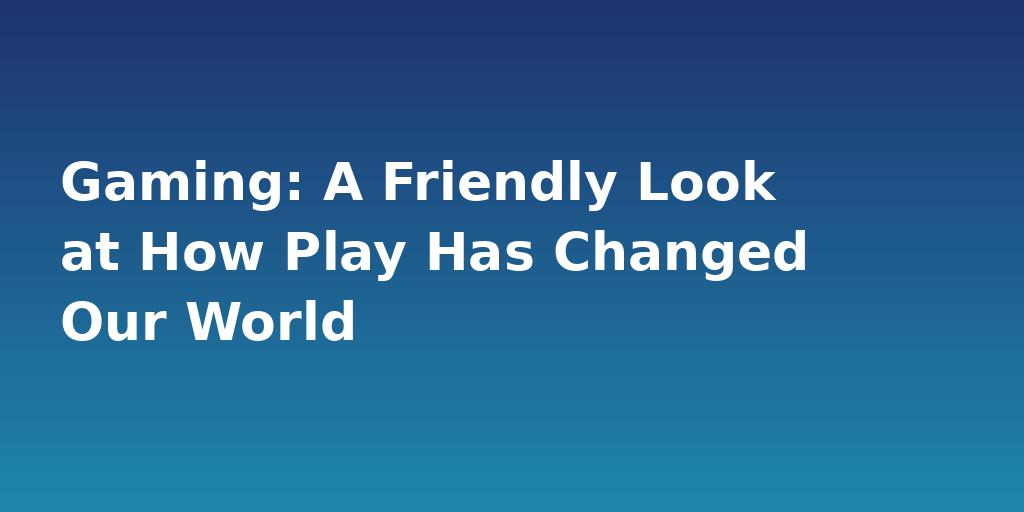

# Gaming: A Friendly Look at How Play Has Changed Our World  

Gaming started as a simple pastime and has grown into a massive, creative, and social force. In this post we’ll walk through the big steps that have shaped gaming, from the noisy arcade to the quiet virtual world in your living room. We’ll also peek at what the future might hold and how games touch culture everywhere.

## The Evolution of Gaming: From Arcades to Virtual Worlds  

In the 1970s and 80s, bright lights and coin‑operated machines filled arcades. Games like *Space Invaders* and *Pac‑Man* gave people a quick burst of fun. When home consoles arrived, families could play together on a TV screen. The graphics were simple, but the excitement was real.

The 1990s brought 3‑D graphics and CD‑based games, allowing richer stories and larger worlds. Titles such as *Super Mario 64* let players explore spaces that felt almost real. As computers became faster, developers built massive open‑world games where you could wander for hours without hitting a wall.

Today, virtual reality headsets and high‑resolution displays let us step inside the game itself. The journey from a single cabinet to fully immersive worlds shows how technology and imagination have grown together.

## The Rise of Indie Games: Creativity Unleashed  

Big studios still make blockbuster hits, but independent developers have carved out a vibrant corner of the industry. With tools that are easier to learn and digital stores that reach millions, small teams can share their ideas without needing huge budgets.

Indie games often focus on unique art styles, personal stories, or clever mechanics. Think of games that use simple shapes to tell deep stories, or puzzles that make you think in new ways. Because they are free from the pressure of massive sales targets, indie creators can take risks and experiment. This freedom has added fresh flavors to the gaming menu and inspired many new developers.

## Multiplayer Revolution: Social Gaming in the Digital Age  

Playing together used to mean sitting side‑by‑side on one couch. Online services changed that forever. Players from opposite sides of the globe can now join the same match, chat, and cooperate in real time.

Games like battle‑royale shooters, cooperative raids, and massive online worlds have turned gaming into a social hub. Friends form squads, guilds, and communities that meet daily. The shared experience builds friendships, teaches teamwork, and even creates new careers as streamers and content creators. Multiplayer has turned a solo hobby into a global conversation.

## The Impact of Cloud Gaming on Accessibility and Performance  

Cloud gaming lets you stream games from powerful servers instead of relying on a high‑end console or PC. All you need is a stable internet connection and a modest device, like a smartphone or a low‑cost laptop.

This model lowers the entry barrier for many players. Someone who cannot afford an expensive console can still enjoy the latest titles. It also means updates and patches happen instantly on the server, so everyone plays the same version. While latency can still be a challenge, improvements in network speed are making cloud gaming smoother every year.

## Future Trends: AI, VR, and the Next Generation of Interactive Experiences  

Artificial intelligence is becoming a tool for designers and players alike. AI can create smarter enemies, generate endless landscapes, or even help write dialogue that adapts to your choices. This promises games that feel more alive and personalized.

Virtual reality continues to improve with lighter headsets and better tracking. As the technology becomes more comfortable, developers will explore deeper storytelling methods that use your whole body, not just your hands.

Looking ahead, we may see hybrid experiences that blend physical toys, AR (augmented reality), and traditional screens. The line between game and reality could blur, offering new ways to learn, exercise, and connect.

## How Gaming Shapes Culture and Community Worldwide  

Games are more than entertainment; they are a language that crosses borders. Players share memes, fan art, and music inspired by their favorite titles. Major events, like worldwide tournaments, draw millions of viewers and turn gamers into celebrities.

In many places, games are used for education, health, and social outreach. Schools use puzzle games to teach math, while therapists use interactive worlds to help patients recover motor skills. Community groups organize charity streams that raise funds for real‑world causes.

Through these activities, gaming builds bridges between different ages, cultures, and backgrounds. It shows how a shared hobby can create empathy and understanding across the globe.

---

Gaming started with a single coin and a blinking screen, and now it touches almost every part of modern life. From indie creators to cloud services, from friends meeting online to AI‑driven adventures, the medium keeps evolving. As we look to the future, one thing is clear: the power of play will continue to shape our culture, our technology, and the way we connect with each other. Happy gaming!

Meta description: Explore how gaming transformed culture, technology, and social connections in a friendly, insightful look.
Tags: gaming, culture, technology, social impact, history


In [10]:
from IPython.display import Image as ShowImage, Markdown, display

display(ShowImage(filename=image_file))
display(Markdown(blog))
print("Meta description:", meta)
print("Tags:", tags)

## Step 10: Save the blog as a markdown file

In [11]:
final_md = "![header image](" + image_file + ")\n\n" + blog + "\n\n---\nTags: " + tags + "\n\nMeta description: " + meta + "\n"

with open("blog.md", "w", encoding="utf-8") as f:
    f.write(final_md)
print("Saved blog.md and", image_file)

try:
    from google.colab import files
    files.download("blog.md")
    files.download(image_file)
except Exception as e:
    print("Download not available here, files are saved in the notebook folder")

Saved blog.md and blog_image.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Key Points

- One topic gives a title, outline, full blog, meta description, tags and a header image (a title banner when the free image service does not answer)
- The word count is approximate. In my first test I asked for 100 words and got 158. If a long blog (300+ words) comes out much shorter than asked, the notebook expands it once (not needed in my run: 725 words for 600 asked)
- The prompt says not to make up statistics or quotes, but always read the blog and fact check before posting
- Image models are bad at collages and text, so the image prompt asks for one single scene. The notebook asks for 3 options at the same time and waits at most 75 seconds, so it can never hang
- The free image service can add its own watermark and its terms are not mine to decide, so check them before using the image commercially. Choose the simple title banner if you want a clean header
- If the image service is slow, busy or down, a simple banner with the title is used so the notebook never stops. This is what happened in my final run, so the 3-option picker is built but I have not seen it return images with the new prompt
- The outline step sometimes counts the title as item 1, so the first section can repeat the title (it did in my run)


Built by Akshat Kesharwani | GitHub: https://github.com/akshatkesharwani-info | Portfolio: https://akshatkesharwani-info.github.io/